# Sensitivity Analysis

The previous notebooks compare the methods with one fixed evaluation protocol and a few fixed gains. This notebook asks three questions.

**Part A: robustness with respect to the evaluation protocol** The recovery threshold, the hold period, the trailing-average window and the warm-up length were arbitrary choices. Section A1 changes them one at a time around the values used so far; Section A2 checks which conclusions of `01_baselines`, `02_sliding_window` and `03_oja` survive every variation; Section A3 checks, seed by seed, which differences between methods are larger than the run-to-run variability.

**Part B: how do the results depend on the gain?** Section B1 sweeps a fixed gain for all methods, at equal stationary noise, and finds the best gain of each regime.

**Part C: how do the results depend on the spectral gap?** The previous notebooks use one gap, $\lambda_1-\lambda_2=4.5$. Section C1 checks whether the equal-noise gains still give equal noise at smaller gaps; Section C2 shows how the best gain of each regime moves with the gap.

The data, seeds and default evaluation settings are those of `01_baselines`.

In [1]:
from pathlib import Path
import sys
import time

# Find the project when Jupyter starts from either its root or notebooks folder.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'methods.py').is_file() and (p / 'data_generators.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Start Jupyter from online_pca_thesis or its notebooks folder.')
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

import plots as ut
from data_generators import generate_stationary, generate_abrupt, generate_smooth_rotation, generate_drift
from methods import (cumulative_pca, incremental_pca, forgetting_pca, rank1_svd_pca,
                     sliding_window_cov_pca, sliding_window_svd_pca, tw_api_pca, oja_pca)
from metrics import axis_error, recovery_delay
from benchmark import write_rows

In [2]:
# Same data settings as 01_baselines
n_samples = 2000
lam1 = 5.0
lam2 = 0.5
theta0 = 0.0
theta1 = np.pi / 3
switch_step = 1000
omega = 0.001
q = 0.0001
dt = 1.0
seeds = range(20)
spectral_gap = lam1 - lam2

# Default evaluation settings of 01_baselines, and the values tried in Part A
default = {'threshold': 0.05, 'hold': 50, 'smooth': 50, 'warmup': 200}
variations = {'threshold': [0.1, 0.05, 0.02, 0.01],
              'hold': [25, 50, 100],
              'smooth': [25, 50, 100],
              'warmup': [100, 200, 400]}

# Three memory levels at equal stationary noise (01_baselines, 02, 03)
gains = [0.005, 0.02, 0.1]   # long to short memory, as in 01_baselines
def window_for(alpha):
    return int(round(2 / alpha - 1))
def oja_gain_for(alpha):
    return alpha / spectral_gap

results_dir = PROJECT_ROOT / 'results' / 'sensitivity'
results_dir.mkdir(parents=True, exist_ok=True)

In [3]:
def make_streams(generator, **kwargs):
    streams = {}
    for run_seed in seeds:
        X_run, theta_run, truth_run = generator(run_seed, n_samples=n_samples, lam1=lam1, lam2=lam2,
                                                theta0=theta0, **kwargs)
        for array in (X_run, theta_run, truth_run):
            array.setflags(write=False)
        streams[run_seed] = (X_run, theta_run, truth_run)
    return streams

streams = {
    'stationary': make_streams(generate_stationary),
    'abrupt': make_streams(generate_abrupt, theta1=theta1, switch_step=switch_step),
    'rotation': make_streams(generate_smooth_rotation, omega=omega, dt=dt),
    'drift': make_streams(generate_drift, Q=q, dt=dt),
}
scenarios = list(streams)

def error_runs(fn, scenario):
    # raw axis errors, one row per seed
    return np.array([axis_error(fn(X_run)[0], truth_run) for X_run, _, truth_run in streams[scenario].values()])

# Part A: robustness to the evaluation protocol

### The methods

One representative of each family, at the three memory levels of the previous notebooks. Within a level all methods have about the same stationary noise: forgetting with gain $\alpha$, windows with $w=2/\alpha-1$, Oja with $\alpha/(\lambda_1-\lambda_2)$ (`02_sliding_window`, Section 7; `03_oja`, Section 2). Cumulative and Incremental PCA have no memory parameter. The errors are computed once; changing the evaluation settings only changes how they are summarized.

In [4]:
def method_set(alpha):
    w = window_for(alpha)
    return {
        'forgetting': lambda X: forgetting_pca(X, alpha),
        'rank-1 SVD forgetting': lambda X: rank1_svd_pca(X, alpha),
        'exact window': lambda X: sliding_window_cov_pca(X, w),
        'rank-1 SVD window': lambda X: sliding_window_svd_pca(X, w),
        'TW-API': lambda X: tw_api_pca(X, w),
        'Oja': lambda X: oja_pca(X, oja_gain_for(alpha)),
    }

def level_name(alpha):
    return f'α={alpha:g} (w={window_for(alpha)}, Oja α={oja_gain_for(alpha):.5f})'

start = time.perf_counter()
errors = {}   # (method, alpha or None, scenario) -> array (seeds, n_samples)
for scenario in scenarios:
    errors['cumulative', None, scenario] = error_runs(cumulative_pca, scenario)
    errors['Incremental PCA', None, scenario] = error_runs(incremental_pca, scenario)
    for alpha in gains:
        for method, fn in method_set(alpha).items():
            errors[method, alpha, scenario] = error_runs(fn, scenario)
print(f'{len(errors)} configurations, {time.perf_counter() - start:.0f} s')

parametric = list(method_set(gains[0]))
all_methods = [('cumulative', None), ('Incremental PCA', None)] + [(m, a) for a in gains for m in parametric]

80 configurations, 67 s


In [5]:
def delays(runs, s):
    return np.array([recovery_delay(e, switch_step, threshold=s['threshold'], window=s['smooth'], hold=s['hold'])
                     for e in runs])

def recovery_summary(runs, s):
    d = delays(runs, s)
    ok = np.isfinite(d)
    return ok.sum(), (float(np.median(d[ok])) if ok.any() else np.nan)

def settings_with(name, value):
    s = dict(default)
    s[name] = value
    return s

def label(method, alpha):
    return method if alpha is None else f'{method}, α={alpha:g}'

## A1. One parameter at a time

### Recovery after the abrupt change

The recovery delay (`metrics.recovery_delay`) depends on three parameters, all chosen by us:

- **Trailing-average window** (`smooth`, default $50$): the raw axis error is noisy, so recovery is judged on its trailing average over the latest `smooth` observations. The average restarts at the change, so it only uses post-change errors; the earliest possible delay is therefore `smooth` observations.
- **Threshold** (`threshold`, default $0.05$): the level of the trailing average below which the estimate counts as recovered. $E=0.05$ corresponds to an angle error of about $13^\circ$.
- **Hold** (`hold`, default $50$): the trailing average must stay at or below the threshold for `hold` consecutive observations, so that a single lucky dip below the threshold is not counted as a recovery. The delay is the **start** of this stable period, not the observation at which it is confirmed.

A run that never satisfies these conditions before the end of the stream counts as not recovered.

The tables use the **middle memory level** of the previous notebooks: forgetting gain $\alpha=0.02$, window $w=99$ and Oja gain $\alpha/(\lambda_1-\lambda_2)\approx0.00444$, which have about the same stationary noise. In the labels, $\alpha$ is the forgetting gain of the level for every method.

For each recovery parameter, the other two keep their default values. Each cell reports the recovered runs out of 20 and the median recovery delay among the recovered runs. The default column is marked with \*.

In [6]:
middle = gains[1]
table_methods = [('cumulative', None), ('Incremental PCA', None)] + [(m, middle) for m in parametric]
for name in ['threshold', 'hold', 'smooth']:
    rows = []
    for method, alpha in table_methods:
        row = [label(method, alpha)]
        for value in variations[name]:
            n_ok, median = recovery_summary(errors[method, alpha, 'abrupt'], settings_with(name, value))
            row.append(f'{n_ok}/20' + (f', {median:.0f}' if n_ok else ''))
        rows.append(row)
    header = [f'{name} (middle memory level)'] + [f'{v}*' if v == default[name] else f'{v}' for v in variations[name]]
    ut.show_table(header, rows)

| threshold (middle memory level) | 0.1 | 0.05* | 0.02 | 0.01 |
| --- | --- | --- | --- | --- |
| cumulative | 0/20 | 0/20 | 0/20 | 0/20 |
| Incremental PCA | 0/20 | 0/20 | 0/20 | 0/20 |
| forgetting, α=0.02 | 20/20, 81 | 20/20, 92 | 20/20, 108 | 20/20, 122 |
| rank-1 SVD forgetting, α=0.02 | 20/20, 102 | 20/20, 116 | 20/20, 144 | 20/20, 160 |
| exact window, α=0.02 | 20/20, 93 | 20/20, 102 | 20/20, 110 | 20/20, 116 |
| rank-1 SVD window, α=0.02 | 20/20, 118 | 20/20, 176 | 10/20, 468 | 1/20, 922 |
| TW-API, α=0.02 | 20/20, 111 | 20/20, 120 | 20/20, 130 | 20/20, 137 |
| Oja, α=0.02 | 20/20, 110 | 20/20, 130 | 20/20, 152 | 20/20, 170 |


| hold (middle memory level) | 25 | 50* | 100 |
| --- | --- | --- | --- |
| cumulative | 0/20 | 0/20 | 0/20 |
| Incremental PCA | 0/20 | 0/20 | 0/20 |
| forgetting, α=0.02 | 20/20, 92 | 20/20, 92 | 20/20, 92 |
| rank-1 SVD forgetting, α=0.02 | 20/20, 116 | 20/20, 116 | 20/20, 116 |
| exact window, α=0.02 | 20/20, 102 | 20/20, 102 | 20/20, 102 |
| rank-1 SVD window, α=0.02 | 20/20, 176 | 20/20, 176 | 20/20, 183 |
| TW-API, α=0.02 | 20/20, 120 | 20/20, 120 | 20/20, 120 |
| Oja, α=0.02 | 20/20, 130 | 20/20, 130 | 20/20, 130 |


| smooth (middle memory level) | 25 | 50* | 100 |
| --- | --- | --- | --- |
| cumulative | 0/20 | 0/20 | 0/20 |
| Incremental PCA | 0/20 | 0/20 | 0/20 |
| forgetting, α=0.02 | 20/20, 72 | 20/20, 92 | 20/20, 132 |
| rank-1 SVD forgetting, α=0.02 | 20/20, 100 | 20/20, 116 | 20/20, 156 |
| exact window, α=0.02 | 20/20, 84 | 20/20, 102 | 20/20, 143 |
| rank-1 SVD window, α=0.02 | 20/20, 174 | 20/20, 176 | 20/20, 200 |
| TW-API, α=0.02 | 20/20, 102 | 20/20, 120 | 20/20, 161 |
| Oja, α=0.02 | 20/20, 114 | 20/20, 130 | 20/20, 166 |


### Warm-up and mean errors

The **warm-up** (default $200$) is the number of initial observations left out of the mean errors. At the start every method has seen only a few observations, and is highly dependant on the initial conditions, so its estimate is poor for reasons that have nothing to do with the regime; leaving these observations out keeps the start-up from dominating the comparison. The warm-up does not affect the recovery delay, which only uses the observations after the change.

The table reports, for the middle memory level, the mean axis error over the observations after the warm-up and over the 20 seeds, for warm-up $100$, $200$ (default) and $400$, written as three values in each cell:

- **Stationary, Rotation, Drift:** the regimes without a single change (the direction is fixed, or moves continuously). The mean is taken from the end of the warm-up to the end of the stream.
- **Abrupt, pre-change:** the abrupt regime before the change, from the end of the warm-up to observation $1000$. The error after the change does not depend on the warm-up, so it is not shown.

If a method's mean error hardly changes between the three warm-ups, its start-up is over well before observation $100$ and the choice of warm-up does not matter for it. A mean that keeps changing means the method's error is still evolving during the stream, so the warm-up decides part of the result.

In [7]:
rows = []
for method, alpha in table_methods:
    row = [label(method, alpha)]
    for regime in ['stationary', 'abrupt (pre-change)', 'rotation', 'drift']:
        cells_ = []
        for warm in variations['warmup']:
            runs = errors[method, alpha, regime.split()[0]]
            value = runs[:, warm:switch_step].mean() if regime.startswith('abrupt') else runs[:, warm:].mean()
            cells_.append(f'{value:.5f}')
        row.append(' / '.join(cells_))
    rows.append(row)
ut.show_table(['Mean E, warm-up 100 / 200* / 400', 'Stationary', 'Abrupt, pre-change', 'Rotation', 'Drift'], rows)

| Mean E, warm-up 100 / 200* / 400 | Stationary | Abrupt, pre-change | Rotation | Drift |
| --- | --- | --- | --- | --- |
| cumulative | 0.00019 / 0.00014 / 0.00009 | 0.00033 / 0.00024 / 0.00015 | 0.28101 / 0.29627 / 0.33027 | 0.03772 / 0.03948 / 0.04263 |
| Incremental PCA | 0.00020 / 0.00015 / 0.00010 | 0.00036 / 0.00026 / 0.00016 | 0.33630 / 0.35459 / 0.39557 | 0.04179 / 0.04376 / 0.04728 |
| forgetting, α=0.02 | 0.00122 / 0.00121 / 0.00118 | 0.00125 / 0.00123 / 0.00116 | 0.00378 / 0.00383 / 0.00374 | 0.00365 / 0.00366 / 0.00362 |
| rank-1 SVD forgetting, α=0.02 | 0.00110 / 0.00108 / 0.00106 | 0.00112 / 0.00109 / 0.00103 | 0.00423 / 0.00428 / 0.00420 | 0.00379 / 0.00379 / 0.00374 |
| exact window, α=0.02 | 0.00124 / 0.00123 / 0.00119 | 0.00126 / 0.00125 / 0.00115 | 0.00380 / 0.00381 / 0.00370 | 0.00468 / 0.00469 / 0.00470 |
| rank-1 SVD window, α=0.02 | 0.00100 / 0.00099 / 0.00096 | 0.00102 / 0.00099 / 0.00091 | 0.01374 / 0.01427 / 0.01512 | 0.00596 / 0.00602 / 0.00608 |
| TW-API, α=0.02 | 0.00110 / 0.00109 / 0.00105 | 0.00112 / 0.00110 / 0.00100 | 0.00444 / 0.00446 / 0.00436 | 0.00481 / 0.00482 / 0.00481 |
| Oja, α=0.02 | 0.00123 / 0.00123 / 0.00121 | 0.00121 / 0.00120 / 0.00114 | 0.00389 / 0.00391 / 0.00380 | 0.00368 / 0.00368 / 0.00365 |


### What the one-at-a-time variations show

- **Threshold.** Changing the threshold changes every delay, as expected: a stricter threshold takes longer to reach. For forgetting PCA the delay goes from $81$ to $122$ between $0.1$ and $0.01$. The order of the methods is the same at every threshold, with one exception: at $0.01$ the exact window ($116$) becomes faster than forgetting ($122$), because a window removes the old data completely while forgetting never does. The threshold also decides whether the rank-1 SVD window counts as recovered: $20/20$ at $0.05$, $10/20$ at $0.02$, $1/20$ at $0.01$. Its persistent error (about $0.04$, `02_sliding_window`, Section 5) lies just below the default threshold.
- **Hold.** It has almost no effect. Since the delay is the start of the stable period (`metrics.recovery_delay`), the hold only decides whether a recovery is confirmed. Once the trailing average is below the threshold it stays there for every method except the rank-1 SVD window, whose error hovers near the threshold ($176$ against $183$ for hold $50$ and $100$).
- **Trailing-average window.** A longer window delays every recovery by a similar amount (forgetting: $72$, $92$, $132$ for $25$, $50$, $100$), because the trailing average needs more post-change samples to forget the large errors right after the change. The order of the methods does not change.
- **Warm-up.** For every method with limited memory the mean errors change by less than about $5\%$ between warm-up $100$ and $400$, and the order of the methods does not change. Only cumulative and Incremental PCA depend on it, because their error is still decreasing (stationary) or increasing (rotation) over the whole stream.

## A2. Which conclusions survive

Each row is a conclusion written in a previous notebook, turned into a test on the stored errors. Each column is one evaluation setting: the default, and every one-at-a-time variation of Section A1. ✓ means the conclusion holds with that setting, ✗ that it does not.

In [8]:
def median_delay(method, alpha, s):
    return recovery_summary(errors[method, alpha, 'abrupt'], s)[1]

def mean_error(method, alpha, scenario, s):
    runs = errors[method, alpha, scenario]
    return runs[:, s['warmup']:].mean()

claims = {
    'Cumulative and Incremental PCA never recover (01)':
        lambda s: all(recovery_summary(errors[m, None, 'abrupt'], s)[0] == 0 for m in ['cumulative', 'Incremental PCA']),
    'Every limited-memory method recovers in 20/20 runs, middle level (01, 02, 03)':
        lambda s: all(recovery_summary(errors[m, middle, 'abrupt'], s)[0] == 20 for m in parametric),
    'Forgetting recovers sooner than the exact window, every level (02, Sec. 7)':
        lambda s: all(median_delay('forgetting', a, s) < median_delay('exact window', a, s) for a in gains),
    'Forgetting recovers sooner than Oja, every level (03, Sec. 3)':
        lambda s: all(median_delay('forgetting', a, s) < median_delay('Oja', a, s) for a in gains),
    'Exact window recovers sooner than TW-API, every level (02, Sec. 5)':
        lambda s: all(median_delay('exact window', a, s) < median_delay('TW-API', a, s) for a in gains),
    'Equal noise: forgetting and exact window within 10% in stationary data, middle level (02)':
        lambda s: abs(mean_error('exact window', middle, 'stationary', s) / mean_error('forgetting', middle, 'stationary', s) - 1) < 0.10,
    'Equal noise: forgetting and Oja within 10% in stationary data, middle level (03)':
        lambda s: abs(mean_error('Oja', middle, 'stationary', s) / mean_error('forgetting', middle, 'stationary', s) - 1) < 0.10,
    'Random drift: forgetting has a lower error than the exact window, every level (02, Sec. 7)':
        lambda s: all(mean_error('forgetting', a, 'drift', s) < mean_error('exact window', a, 'drift', s) for a in gains),
    'Rank-1 SVD window has the largest rotation error among the windows, every level (02)':
        lambda s: all(mean_error('rank-1 SVD window', a, 'rotation', s) > max(mean_error('exact window', a, 'rotation', s),
                                                                             mean_error('TW-API', a, 'rotation', s)) for a in gains),
}

settings_list = [('default', dict(default))]
for name, values in variations.items():
    for value in values:
        if value != default[name]:
            settings_list.append((f'{name}={value}', settings_with(name, value)))

rows, csv_rows = [], []
for claim, test in claims.items():
    outcome = [bool(test(s)) for _, s in settings_list]
    rows.append([claim] + ['✓' if o else '✗' for o in outcome])
    csv_rows.append({'claim': claim, **{n: o for (n, _), o in zip(settings_list, outcome)}})
ut.show_table(['Conclusion'] + [n for n, _ in settings_list], rows)
write_rows(results_dir / 'claims_by_setting.csv', csv_rows)

| Conclusion | default | threshold=0.1 | threshold=0.02 | threshold=0.01 | hold=25 | hold=100 | smooth=25 | smooth=100 | warmup=100 | warmup=400 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Cumulative and Incremental PCA never recover (01) | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| Every limited-memory method recovers in 20/20 runs, middle level (01, 02, 03) | ✓ | ✓ | ✗ | ✗ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| Forgetting recovers sooner than the exact window, every level (02, Sec. 7) | ✓ | ✓ | ✓ | ✗ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| Forgetting recovers sooner than Oja, every level (03, Sec. 3) | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| Exact window recovers sooner than TW-API, every level (02, Sec. 5) | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| Equal noise: forgetting and exact window within 10% in stationary data, middle level (02) | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| Equal noise: forgetting and Oja within 10% in stationary data, middle level (03) | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| Random drift: forgetting has a lower error than the exact window, every level (02, Sec. 7) | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |
| Rank-1 SVD window has the largest rotation error among the windows, every level (02) | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ | ✓ |


Saved: C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sensitivity\claims_by_setting.csv


### What survives

- **Seven of the nine conclusions hold for every setting tried.**
  - Cumulative methods never recover.
  - Forgetting recovers sooner than Oja.
  - The exact window recovers sooner than TW-API.
  - The equal-noise matchings hold within $10\%$.
  - Forgetting beats the window under random drift.
  - The rank-1 SVD window has the largest rotation error.
- **"Every limited-memory method recovers in 20/20 runs" depends on the threshold.** It fails for thresholds of $0.02$ or less, because of the rank-1 SVD window. The default threshold hides its persistent error. The mean errors of `02_sliding_window` do show it.
- **"Forgetting recovers sooner than the exact window" depends on the threshold.** It holds for thresholds down to $0.02$ but not at $0.01$. The statement in `02_sliding_window`, Section 7, should be read with this qualification. The post-change **error**, which does not use a threshold, favours forgetting in every case (Section A3).

## A3. Seed by seed

All methods see the same 20 streams, so two methods can be compared on each stream. For each pair and each measure, the table reports in how many of the 20 seeds the first method is better, and the mean difference (first minus second) with a 95% interval, mean $\pm\,2.09\times\mathrm{SD}/\sqrt{20}$ (Student $t$ with 19 degrees of freedom). An interval that does not contain zero indicates a difference larger than the run-to-run variability. Default evaluation settings, middle memory level.

**How to read (first row for example)**:
- First better in 20/20: on every one of the 20 streams, forgetting recovered sooner than the window.
- −10.10: on average forgetting is about 10 steps faster.
± 1.74: the uncertainty of that average, given how much the 20 differences vary. The true difference is very probably between −11.8 and −8.4 steps. (Technically it's a 95% interval: mean ± 2.093 × SD/√20. The value 2.093 comes from the Student t distribution with 19 degrees of freedom, the usual factor for 20 values.)
- Clear difference: yes: the interval doesn't contain 0, so the difference is larger than what luck alone would produce.

In [9]:
s = dict(default)
measures = {
    'recovery delay (abrupt)': lambda m: delays(errors[m, middle, 'abrupt'], s),
    'post-change error (abrupt)': lambda m: errors[m, middle, 'abrupt'][:, switch_step:].mean(axis=1),
    'stationary error': lambda m: errors[m, middle, 'stationary'][:, s['warmup']:].mean(axis=1),
    'rotation error': lambda m: errors[m, middle, 'rotation'][:, s['warmup']:].mean(axis=1),
    'drift error': lambda m: errors[m, middle, 'drift'][:, s['warmup']:].mean(axis=1),
}
pairs = [('forgetting', 'exact window'), ('forgetting', 'Oja'), ('exact window', 'TW-API')]

rows = []
for first, second in pairs:
    for name, measure in measures.items():
        a, b = measure(first), measure(second)
        both = np.isfinite(a) & np.isfinite(b)
        diff = a[both] - b[both]
        half = 2.093 * diff.std(ddof=1) / np.sqrt(len(diff))
        scale = 1 if name.startswith('recovery') else 1e3
        unit = 'steps' if name.startswith('recovery') else '×1e-3'
        rows.append([f'{first} vs {second}', name, f'{(diff < 0).sum()}/{len(diff)}',
                     f'{scale * diff.mean():+.2f} ± {scale * half:.2f} {unit}',
                     'yes' if abs(diff.mean()) > half else 'no'])
ut.show_table(['Pair', 'Measure (lower is better)', 'First better in', 'Mean difference (95%)', 'Clear difference'], rows)

| Pair | Measure (lower is better) | First better in | Mean difference (95%) | Clear difference |
| --- | --- | --- | --- | --- |
| forgetting vs exact window | recovery delay (abrupt) | 20/20 | -10.10 ± 1.74 steps | yes |
| forgetting vs exact window | post-change error (abrupt) | 20/20 | -8.21 ± 0.60 ×1e-3 | yes |
| forgetting vs exact window | stationary error | 10/20 | -0.02 ± 0.05 ×1e-3 | no |
| forgetting vs exact window | rotation error | 8/20 | +0.01 ± 0.05 ×1e-3 | no |
| forgetting vs exact window | drift error | 20/20 | -1.04 ± 0.15 ×1e-3 | yes |
| forgetting vs Oja | recovery delay (abrupt) | 20/20 | -39.65 ± 7.42 steps | yes |
| forgetting vs Oja | post-change error (abrupt) | 20/20 | -12.33 ± 2.24 ×1e-3 | yes |
| forgetting vs Oja | stationary error | 12/20 | -0.02 ± 0.04 ×1e-3 | no |
| forgetting vs Oja | rotation error | 11/20 | -0.09 ± 0.08 ×1e-3 | yes |
| forgetting vs Oja | drift error | 12/20 | -0.03 ± 0.06 ×1e-3 | no |
| exact window vs TW-API | recovery delay (abrupt) | 20/20 | -17.55 ± 1.91 steps | yes |
| exact window vs TW-API | post-change error (abrupt) | 20/20 | -8.07 ± 0.67 ×1e-3 | yes |
| exact window vs TW-API | stationary error | 0/20 | +0.14 ± 0.03 ×1e-3 | yes |
| exact window vs TW-API | rotation error | 20/20 | -0.65 ± 0.05 ×1e-3 | yes |
| exact window vs TW-API | drift error | 17/20 | -0.13 ± 0.05 ×1e-3 | yes |


### Which differences are larger than the run-to-run variability

- **Forgetting against the exact window.** Forgetting is better in all 20 seeds after the abrupt change (delay $-10$ steps, post-change error $-8\times10^{-3}$) and under random drift. In stationary data and smooth rotation there is no difference (10/20 and 8/20 seeds, intervals containing zero), which confirms the equal-noise and equal-mean-age matching.
- **Forgetting against Oja.** Forgetting recovers sooner in all 20 seeds (about $40$ steps). In stationary data and drift there is no difference. In rotation the difference is just outside the interval but tiny ($-0.09\times10^{-3}$, 11/20 seeds), so it should not be read as a real advantage.
- **Exact window against TW-API.** TW-API is less noisy in stationary data in every seed ($+0.14\times10^{-3}$ for the window), and the exact window is better in every other measure. This confirms the "extra smoothing, extra lag" description of `02_sliding_window`.

With 20 seeds, the differences reported as conclusions in the previous notebooks are clear.

# Part B: the fixed gain

## B1. Sweep at equal noise

Sweep all possible gains to find the best one for each regime.

All methods on a common memory axis: the forgetting gain $\alpha$, with windows of length $w=2/\alpha-1$ and Oja gain $\alpha/(\lambda_1-\lambda_2)$, so that at each $\alpha$ the methods have about the same stationary noise. The rank-1 SVD window is left out (its persistent error is studied in `02_sliding_window`, Section 5). Measures: mean error after warm-up for stationary, rotation and drift, and the post-change error for the abrupt regime.

In [10]:
grid = [0.002, 0.003, 0.005, 0.0075, 0.01, 0.015, 0.02, 0.03, 0.05, 0.1, 0.2, 0.3]
sweep_methods = {
    'forgetting': lambda a: (lambda X: forgetting_pca(X, a)),
    'rank-1 SVD forgetting': lambda a: (lambda X: rank1_svd_pca(X, a)),
    'exact window': lambda a: (lambda X: sliding_window_cov_pca(X, window_for(a))),
    'TW-API': lambda a: (lambda X: tw_api_pca(X, window_for(a))),
    'Oja': lambda a: (lambda X: oja_pca(X, oja_gain_for(a))),
}
regime_measure = {
    'stationary': lambda r: r[:, default['warmup']:].mean(),
    'abrupt (post-change)': lambda r: r[:, switch_step:].mean(),
    'rotation': lambda r: r[:, default['warmup']:].mean(),
    'drift': lambda r: r[:, default['warmup']:].mean(),
}

start = time.perf_counter()
sweep = {}   # (method, regime, alpha) -> mean error
for regime, measure in regime_measure.items():
    scenario = regime.split()[0]
    for method, make in sweep_methods.items():
        for a in grid:
            sweep[method, regime, a] = measure(error_runs(make(a), scenario))
print(f'{len(sweep)} sweep points, {time.perf_counter() - start:.0f} s')
write_rows(results_dir / 'fixed_gain_sweep.csv',
           [{'method': m, 'regime': r, 'alpha': a, 'window': window_for(a), 'oja_gain': oja_gain_for(a), 'mean_error': v}
            for (m, r, a), v in sweep.items()])

240 sweep points, 232 s
Saved: C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sensitivity\fixed_gain_sweep.csv


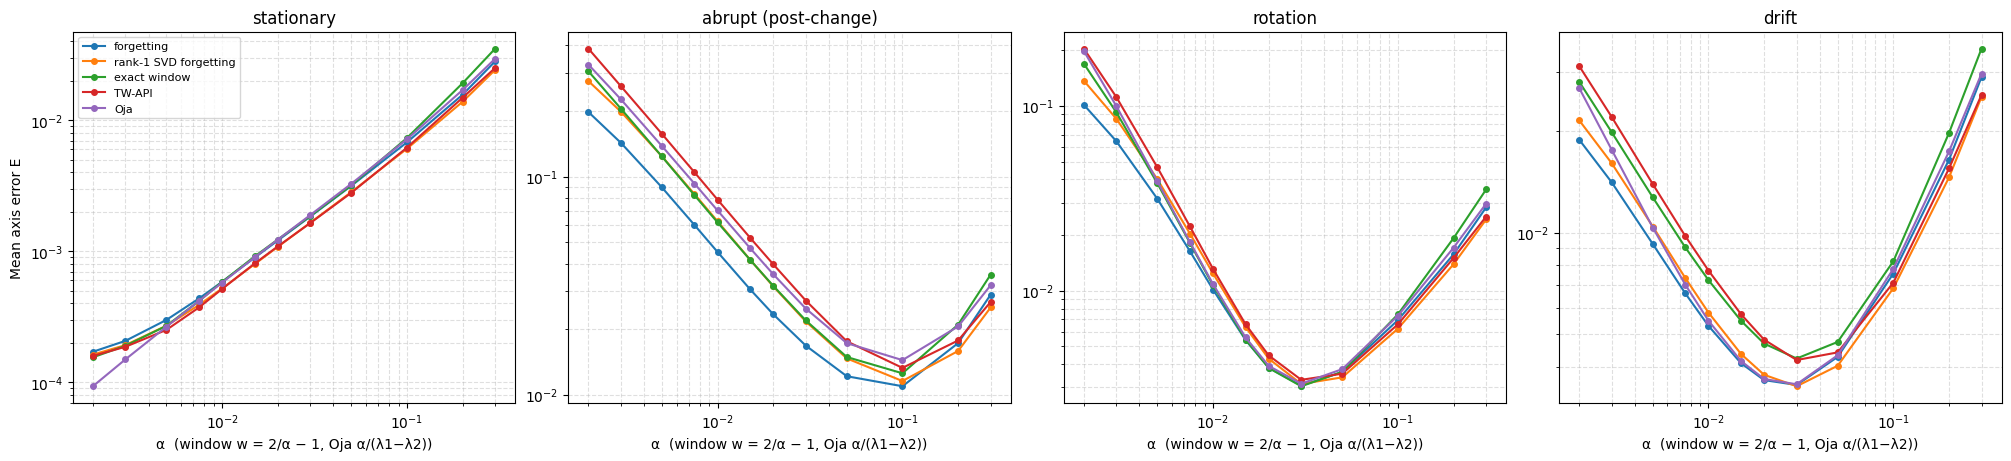

| Regime | Method | Best α on the grid | Mean E at best α |
| --- | --- | --- | --- |
| stationary | forgetting | 0.002 (edge of grid) | 0.00017 |
| stationary | rank-1 SVD forgetting | 0.002 (edge of grid) | 0.00016 |
| stationary | exact window | 0.002 (edge of grid) | 0.00016 |
| stationary | TW-API | 0.002 (edge of grid) | 0.00016 |
| stationary | Oja | 0.002 (edge of grid) | 0.00009 |
| abrupt (post-change) | forgetting | 0.1 | 0.01096 |
| abrupt (post-change) | rank-1 SVD forgetting | 0.1 | 0.01158 |
| abrupt (post-change) | exact window | 0.1 | 0.01256 |
| abrupt (post-change) | TW-API | 0.1 | 0.01330 |
| abrupt (post-change) | Oja | 0.1 | 0.01444 |
| rotation | forgetting | 0.03 | 0.00306 |
| rotation | rank-1 SVD forgetting | 0.03 | 0.00313 |
| rotation | exact window | 0.03 | 0.00304 |
| rotation | TW-API | 0.03 | 0.00329 |
| rotation | Oja | 0.03 | 0.00314 |
| drift | forgetting | 0.03 | 0.00354 |
| drift | rank-1 SVD forgetting | 0.03 | 0.00351 |
| drift | exact window | 0.03 | 0.00424 |
| drift | TW-API | 0.03 | 0.00419 |
| drift | Oja | 0.03 | 0.00355 |


In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), constrained_layout=True)
for ax, regime in zip(axes, regime_measure):
    for method in sweep_methods:
        ax.loglog(grid, [sweep[method, regime, a] for a in grid], marker='o', markersize=4, label=method)
    ax.set_title(regime)
    ax.set_xlabel('α  (window w = 2/α − 1, Oja α/(λ1−λ2))')
    ax.grid(True, which='both', linestyle='--', alpha=0.4)
axes[0].set_ylabel('Mean axis error E')
axes[0].legend(fontsize=8)
plt.show()

rows = []
for regime in regime_measure:
    for method in sweep_methods:
        values = [sweep[method, regime, a] for a in grid]
        best = int(np.argmin(values))
        edge = ' (edge of grid)' if best in (0, len(grid) - 1) else ''
        rows.append([regime, method, f'{grid[best]:g}{edge}', f'{values[best]:.5f}'])
ut.show_table(['Regime', 'Method', 'Best α on the grid', 'Mean E at best α'], rows)

### What the sweep shows

- **Each regime prefers a different gain, and all methods agree on which.** On this grid the best gain is the smallest one in stationary data (more memory is always better), $\alpha=0.1$ for the error after the abrupt change, and $\alpha=0.03$ for smooth rotation and random drift. The same optimum appears for every method, because at equal noise they share the memory axis.
- **At the optimum the methods are close**, except under random drift, where the windows ($0.0042$) are worse than the forgetting methods and Oja ($0.0035$).
- **A caveat on the smallest gains, from the initialization of Oja.** All streams start with the true axis at $\theta_0=0$, and Oja starts from the direction $(1,0)$, which is the true axis. With a very small gain Oja moves little, so its stationary error at $\alpha=0.002$ ($0.00009$) is lower than that of the other methods. This is not a real advantage. The next cell repeats the stationary runs with the true axis starting at $1$ radian instead of $0$: the same Oja gain then gives a stationary error of about $0.1$, because the direction has not converged within $2000$ observations, and the Oja gain $0.00111$ of `03_oja` ($\alpha=0.005$) gives $0.018$ instead of $0.00027$. For the larger gains ($\alpha\ge0.02$) the starting direction makes no difference. The covariance-based methods are not affected, because they do not keep a starting direction. TW-API also starts from $(1,0)$, but at the start its effective gain is large and it aligns with the data within a few tens of steps, so its error after warm-up does not depend on the starting axis.
- **No fixed gain is good for every regime.** The best gain for stationary data is the worst choice after a change, and the other way round; this is the trade-off that motivates choosing the gain over time.

In [12]:
# Check of the caveat above: stationary data with the true axis starting at 0 (as in the rest of the notebook)
# or at 1 rad. Every method keeps its usual start (Oja and TW-API from the direction (1, 0)).
start_axes = [0.0, 1.0]
check_gains = [a for a in grid if a <= 0.02]
check_streams = {t0: [generate_stationary(run_seed, n_samples=n_samples, lam1=lam1, lam2=lam2, theta0=t0)
                      for run_seed in seeds] for t0 in start_axes}

def stationary_after_warmup(fn, t0):
    # mean axis error after the warm-up, averaged over the 20 seeds
    return np.mean([axis_error(fn(X_run)[0], truth_run)[default['warmup']:].mean()
                    for X_run, _, truth_run in check_streams[t0]])

rows = []
for a in check_gains:
    row = [f'{a:g}']
    for name, fn in [('Oja', lambda X: oja_pca(X, oja_gain_for(a))),
                     ('forgetting', lambda X: forgetting_pca(X, a)),
                     ('TW-API', lambda X: tw_api_pca(X, window_for(a)))]:
        row.append(' / '.join(f'{stationary_after_warmup(fn, t0):.5f}' for t0 in start_axes))
    rows.append(row)
ut.show_table(['α', 'Oja (axis at 0 / at 1 rad)', 'Forgetting (axis at 0 / at 1 rad)',
               'TW-API (axis at 0 / at 1 rad)'], rows)

| α | Oja (axis at 0 / at 1 rad) | Forgetting (axis at 0 / at 1 rad) | TW-API (axis at 0 / at 1 rad) |
| --- | --- | --- | --- |
| 0.002 | 0.00009 / 0.10745 | 0.00017 / 0.00017 | 0.00016 / 0.00016 |
| 0.003 | 0.00015 / 0.05453 | 0.00021 / 0.00021 | 0.00019 / 0.00019 |
| 0.005 | 0.00027 / 0.01788 | 0.00030 / 0.00030 | 0.00025 / 0.00025 |
| 0.0075 | 0.00042 / 0.00547 | 0.00044 / 0.00044 | 0.00037 / 0.00038 |
| 0.01 | 0.00058 / 0.00217 | 0.00058 / 0.00058 | 0.00052 / 0.00052 |
| 0.015 | 0.00090 / 0.00110 | 0.00089 / 0.00089 | 0.00081 / 0.00082 |
| 0.02 | 0.00123 / 0.00127 | 0.00121 / 0.00121 | 0.00109 / 0.00110 |


Each cell gives the stationary error with the true axis starting at $0$ (left) and at $1$ rad (right). If the two numbers are equal, the result does not depend on where the method started.

- **Forgetting and TW-API:** the two numbers are almost at every gain, so the start does not matter.
- **Oja:** at small gains the two numbers are very different ($0.00009$ against $0.107$ at $\alpha=0.002$): Oja moves so slowly that its result depends on the lucky start on the true axis. From $\alpha\approx0.02$ the two numbers agree and equal those of forgetting PCA.

Oja's stationary errors in the sweep are therefore reliable from $\alpha\approx0.02$ up; below that they are favoured by the start.

# Part C: the spectral gap

All previous results use one spectral gap, $\lambda_1-\lambda_2=4.5$. The gap decides how clearly the data define the leading direction: with a small gap the two variances are close, the direction is harder to estimate, and every method is noisier. Two questions:

- **C1.** The equal-noise gains (windows $w=2/\alpha-1$, Oja $\alpha/(\lambda_1-\lambda_2)$) were checked at gap $4.5$ only. Do they still give the same stationary noise at smaller gaps? For Oja this is the real test of the scaling by the gap: at a single gap, dividing by the gap cannot be told apart from dividing by the number $4.5$.
- **C2.** How does the best gain of each regime move with the gap?

**Settings.** $\lambda_1=5$ is fixed and $\lambda_2\in\{0.5,1.5,2.5,3.5\}$, so the gap is $4.5$, $3.5$, $2.5$ or $1.5$ (the total variance also grows with $\lambda_2$; this does not change the axis error). The other data settings, the seeds and the regimes are those of Part B. Three methods, one per family: forgetting PCA, the exact window, and Oja with the gain $\alpha/(\lambda_1-\lambda_2)$ recomputed at each gap.

**Measures.** For stationary data, rotation and drift the error is averaged **from observation $1000$**, not from the warm-up of $200$ used elsewhere. With a small gain, Oja's error depends on its lucky start on the true axis for several hundred observations (see the check after Part B1), and this would distort the comparison between gaps; from observation $1000$ the start no longer matters. After the abrupt change the measure is the post-change error, as in Part B1; the recovery delay is not used, because at small gaps the stationary noise is above the recovery threshold.

In [13]:
gap_lam2 = [0.5, 1.5, 2.5, 3.5]                     # lam1 = 5 fixed: gaps 4.5, 3.5, 2.5, 1.5
gap_values = [lam1 - l2 for l2 in gap_lam2]         
gap_grid = [0.003, 0.005, 0.01, 0.02, 0.03, 0.05, 0.1, 0.2]
late_start = 1000                                    # first observation of the averages (see the text above)

def gap_streams(lam2_c):
    # the four regimes of Part B with lam2 = lam2_c; same seeds
    def make(generator, **kwargs):
        return [generator(run_seed, n_samples=n_samples, lam1=lam1, lam2=lam2_c, theta0=theta0, **kwargs)
                for run_seed in seeds]
    return {'stationary': make(generate_stationary),
            'abrupt': make(generate_abrupt, theta1=theta1, switch_step=switch_step),
            'rotation': make(generate_smooth_rotation, omega=omega, dt=dt),
            'drift': make(generate_drift, Q=q, dt=dt)}

gap_methods = {
    'forgetting': lambda a, gap: (lambda X: forgetting_pca(X, a)),
    'exact window': lambda a, gap: (lambda X: sliding_window_cov_pca(X, window_for(a))),
    'Oja': lambda a, gap: (lambda X: oja_pca(X, a / gap)),     # gain rescaled with the gap of the data
}
gap_regimes = {   # regime -> (scenario, observations averaged)
    'stationary': ('stationary', slice(late_start, None)),
    'abrupt (post-change)': ('abrupt', slice(switch_step, None)),
    'rotation': ('rotation', slice(late_start, None)),
    'drift': ('drift', slice(late_start, None)),
}

start = time.perf_counter()
gap_sweep = {}   # (method, regime, gap, alpha) -> mean error over the 20 seeds
for lam2_c, gap in zip(gap_lam2, gap_values):
    data = gap_streams(lam2_c)
    for regime, (scenario, period) in gap_regimes.items():
        for method, make in gap_methods.items():
            for a in gap_grid:
                fn = make(a, gap)
                gap_sweep[method, regime, gap, a] = np.mean([axis_error(fn(X_run)[0], truth_run)[period].mean()
                                                             for X_run, _, truth_run in data[scenario]])
print(f'{len(gap_sweep)} sweep points, {time.perf_counter() - start:.0f} s')
write_rows(results_dir / 'gap_sweep.csv',
           [{'method': m, 'regime': r, 'lam1': lam1, 'lam2': lam1 - g, 'spectral_gap': g, 'alpha': a,
             'window': window_for(a), 'oja_gain': a / g, 'first_observation_averaged': gap_regimes[r][1].start + 1,
             'mean_error': v} for (m, r, g, a), v in gap_sweep.items()])

384 sweep points, 357 s
Saved: C:\Users\mesie\OneDrive\Desktop\TESI\online_pca_thesis\results\sensitivity\gap_sweep.csv


## C1. Equal noise at every gap

Stationary error of Oja (gain $\alpha/(\lambda_1-\lambda_2)$) and of the exact window ($w=2/\alpha-1$), divided by that of forgetting PCA with the same $\alpha$. A ratio of $1$ means equal noise.

In the previous notebooks Oja and the exact window were given gains with the same stationary noise as forgetting PCA: Oja with $\alpha/(\lambda_1-\lambda_2)$ and the window with $w=2/\alpha-1$. This matching was only checked at gap $4.5$. The table checks it at every gap.

**How to read the table.** Each row is a gap, each column a forgetting gain $\alpha$ (the Oja gain and the window are derived from it). Each cell contains two ratios:

- **first number:** stationary error of Oja divided by that of forgetting PCA;
- **second number:** stationary error of the exact window divided by that of forgetting PCA.

A ratio of $1$ means the two methods are equally noisy, so the matching works; $1.10$ means $10\%$ noisier than forgetting PCA, $0.90$ means $10\%$ less noisy. The column "E forgetting, α=0.02" gives the actual error of forgetting PCA at the middle gain, to show how much noisier all methods become as the gap shrinks.

For example, at gap $4.5$ and $\alpha=0.02$ the cell "1.04 / 1.02" means that Oja is $4\%$ and the window $2\%$ noisier than forgetting PCA.

What we are looking for is that no matter the gap, when nothing changes, they're Oja and sliding window methods are exactly as noisy as forgetting PCA, and they do not change because of a different spectral gap.

In [14]:
rows = []
for gap in gap_values:
    row = [f'{gap:g}', f"{gap_sweep['forgetting', 'stationary', gap, 0.02]:.5f}"]
    for a in gap_grid:
        f = gap_sweep['forgetting', 'stationary', gap, a]
        row.append(f"{gap_sweep['Oja', 'stationary', gap, a] / f:.2f} / {gap_sweep['exact window', 'stationary', gap, a] / f:.2f}")
    rows.append(row)
ut.show_table(['Gap', 'E forgetting, α=0.02'] + [f'α={a:g}' for a in gap_grid], rows)
print('Each cell: Oja / forgetting and exact window / forgetting, stationary error from observation', late_start + 1)

| Gap | E forgetting, α=0.02 | α=0.003 | α=0.005 | α=0.01 | α=0.02 | α=0.03 | α=0.05 | α=0.1 | α=0.2 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 4.5 | 0.00119 | 1.00 / 0.89 | 1.02 / 0.93 | 1.03 / 1.02 | 1.04 / 1.02 | 1.05 / 1.00 | 1.06 / 1.01 | 1.08 / 1.08 | 1.10 / 1.22 |
| 3.5 | 0.00602 | 1.00 / 0.89 | 1.02 / 0.93 | 1.02 / 1.02 | 1.03 / 1.01 | 1.04 / 1.00 | 1.03 / 1.02 | 0.98 / 1.09 | 0.94 / 1.13 |
| 2.5 | 0.02069 | 1.00 / 0.89 | 1.02 / 0.92 | 1.00 / 1.02 | 0.99 / 1.01 | 0.96 / 1.01 | 0.92 / 1.00 | 0.97 / 1.05 | 1.20 / 1.04 |
| 1.5 | 0.09344 | 0.97 / 0.92 | 0.96 / 0.90 | 0.87 / 0.99 | 0.89 / 0.98 | 1.00 / 1.01 | 1.25 / 1.01 | 1.29 / 1.02 | 1.29 / 1.02 |


Each cell: Oja / forgetting and exact window / forgetting, stationary error from observation 1001


### Results

- **Every method becomes much noisier as the gap shrinks.** At $\alpha=0.02$ the stationary error of forgetting PCA is $0.0012$ at gap $4.5$, $0.0060$ at $3.5$, $0.021$ at $2.5$ and $0.093$ at $1.5$: $80$ times larger between the largest and the smallest gap.
- **Oja's scaled gain gives equal noise down to gap $2.5$.** At gaps $4.5$, $3.5$ and $2.5$ the ratio Oja / forgetting is between $0.92$ and $1.10$ for every gain up to $\alpha=0.1$ (at $\alpha=0.2$ it reaches $1.20$ at gap $2.5$).
- **At gap $1.5$ the matching is less accurate:** the ratio is $0.87$–$0.89$ for $\alpha=0.01$–$0.02$ and $1.25$–$1.29$ for $\alpha\ge0.05$. With a small gap the two variances are close ($\lambda_2=3.5$ against $\lambda_1=5$): the cloud of data is almost round, each observation says little about the direction, and every method becomes much noisier ($E=0.09$ at $\alpha=0.02$, an angle error of about $18^\circ$).

## C2. The best gain at each gap

We look to see if the best gain found by each method also changes as a result of the different spectral gap.

For each regime and gap, the gain of the grid with the lowest error, and that error. The equal-noise matching puts the three methods on the same gain axis, so their best gains can be compared.

| Regime | Method | gap 4.5 | gap 3.5 | gap 2.5 | gap 1.5 |
| --- | --- | --- | --- | --- | --- |
| stationary | forgetting | 0.003* (0.0002) | 0.003* (0.0008) | 0.003* (0.0026) | 0.003* (0.0106) |
| stationary | exact window | 0.003* (0.0001) | 0.003* (0.0007) | 0.003* (0.0023) | 0.003* (0.0098) |
| stationary | Oja | 0.003* (0.0002) | 0.003* (0.0008) | 0.003* (0.0026) | 0.003* (0.0102) |
| abrupt (post-change) | forgetting | 0.1 (0.0110) | 0.03 (0.0245) | 0.02 (0.0439) | 0.01 (0.0962) |
| abrupt (post-change) | exact window | 0.1 (0.0126) | 0.05 (0.0280) | 0.02 (0.0505) | 0.01 (0.1021) |
| abrupt (post-change) | Oja | 0.1 (0.0144) | 0.05 (0.0305) | 0.03 (0.0544) | 0.02 (0.1321) |
| rotation | forgetting | 0.03 (0.0031) | 0.02 (0.0089) | 0.01 (0.0206) | 0.01 (0.0551) |
| rotation | exact window | 0.03 (0.0030) | 0.02 (0.0089) | 0.01 (0.0206) | 0.01 (0.0529) |
| rotation | Oja | 0.03 (0.0031) | 0.02 (0.0090) | 0.01 (0.0210) | 0.01 (0.0532) |
| drift | forgetting | 0.03 (0.0035) | 0.01 (0.0079) | 0.005 (0.0145) | 0.003* (0.0283) |
| drift | exact window | 0.03 (0.0042) | 0.01 (0.0104) | 0.005 (0.0171) | 0.003* (0.0293) |
| drift | Oja | 0.03 (0.0035) | 0.01 (0.0081) | 0.005 (0.0153) | 0.003* (0.0295) |


Best α on the grid (mean error at that α); * = edge of the grid


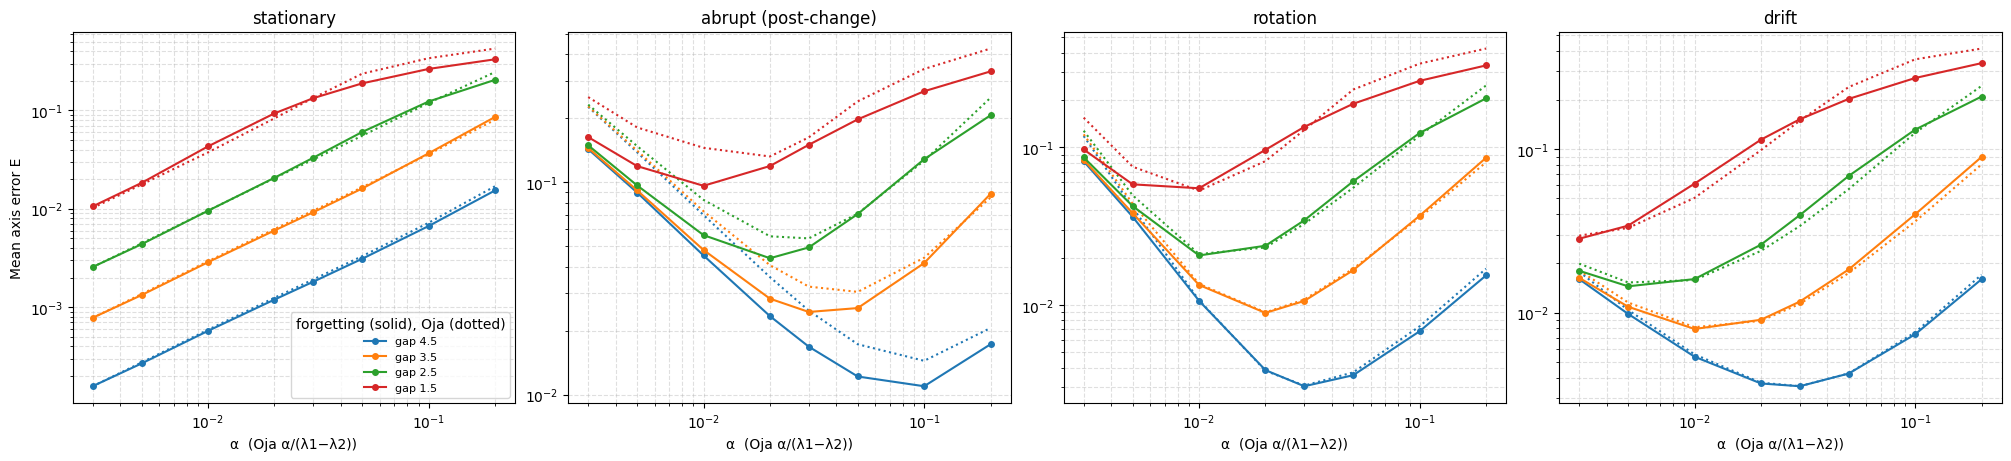

In [15]:
rows = []
for regime in gap_regimes:
    for method in gap_methods:
        row = [regime, method]
        for gap in gap_values:
            values = [gap_sweep[method, regime, gap, a] for a in gap_grid]
            best = int(np.argmin(values))
            edge = '*' if best in (0, len(gap_grid) - 1) else ''
            row.append(f'{gap_grid[best]:g}{edge} ({values[best]:.4f})')
        rows.append(row)
ut.show_table(['Regime', 'Method'] + [f'gap {g:g}' for g in gap_values], rows)
print('Best α on the grid (mean error at that α); * = edge of the grid')

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), constrained_layout=True)
for ax, regime in zip(axes, gap_regimes):
    for gap in gap_values:
        ax.loglog(gap_grid, [gap_sweep['forgetting', regime, gap, a] for a in gap_grid], marker='o', markersize=4,
                  label=f'gap {gap:g}')
        ax.loglog(gap_grid, [gap_sweep['Oja', regime, gap, a] for a in gap_grid], linestyle=':', color=ax.lines[-1].get_color())
    ax.set_title(regime)
    ax.set_xlabel('α  (Oja α/(λ1−λ2))')
    ax.grid(True, which='both', linestyle='--', alpha=0.4)
axes[0].set_ylabel('Mean axis error E')
axes[0].legend(fontsize=8, title='forgetting (solid), Oja (dotted)')
plt.show()

### What C2 shows

- **The smaller the gap, the smaller the best gain (the longer the memory).** For forgetting PCA, the best gain after the abrupt change goes from $0.1$ at gap $4.5$ to $0.03$, $0.02$ and $0.01$; in smooth rotation from $0.03$ to $0.02$, $0.01$ and $0.01$; under random drift from $0.03$ to $0.01$, $0.005$ and $0.003$ (the edge of the grid, so the best gain at gap $1.5$ may be even smaller). In stationary data the smallest gain of the grid is always the best.
- **The reason is the noise:** with a small gap each new observation says less about the direction, so the estimate needs a longer memory to average the noise out, at the price of a slower reaction to changes.
- **The three methods agree on the best gain**, as at gap $4.5$ (Part B1). The only differences are one grid step after the abrupt change, where Oja prefers a slightly larger gain ($0.05$, $0.03$, $0.02$ at gaps $3.5$, $2.5$, $1.5$).
- **Oja remains the slowest after the abrupt change at every gap.** At the best gain of each method its post-change error is $31\%$, $24\%$, $24\%$ and $37\%$ above that of forgetting PCA for gaps $4.5$, $3.5$, $2.5$ and $1.5$.
- **Consequence for the choice of the gain.** The best fixed gain depends not only on the regime (Part B) but also on how well the data separate the two directions. A gain chosen at one gap can be far from the best at another: for random drift the best gain changes by a factor of $10$ between gap $4.5$ and gap $1.5$. A rule for choosing the gain over time has to react to the noise level of the data, not only to the changes of the direction.

# Summary

**Evaluation protocol (Part A).**
- Most conclusions of the previous notebooks do not depend on the recovery threshold, the hold, the trailing-average window or the warm-up.
- Two depend on the threshold:
  - the rank-1 SVD window is counted as "recovered" only because the default threshold ($0.05$) is above its persistent error;
  - forgetting recovers sooner than the exact window for thresholds down to $0.02$, but not at $0.01$. The post-change error favours forgetting in every case.
- The hold has almost no effect now that the delay is the start of the stable period. The trailing-average window shifts all delays by a similar amount.
- Seed by seed, every difference stated as a conclusion is clear (in 17 to 20 of the 20 seeds), and every equality ("same noise", "same lag") is compatible with zero.

**Fixed gain (Part B).**
- At equal noise all methods have the same best gain in each regime. It is the smallest gain in stationary data, $\alpha\approx0.1$ after the abrupt change, and $\alpha\approx0.03$ for smooth rotation and random drift.
- No fixed gain is good for every regime.

**Spectral gap (Part C).**
- As the gap shrinks every method becomes much noisier ($80$ times between gap $4.5$ and $1.5$ at $\alpha=0.02$). The equal-noise gains still give equal noise down to gap $2.5$ (Oja within $10\%$, with its gain recomputed at each gap); at gap $1.5$ the Oja matching is off by up to about $30\%$.
- The best gain of every regime with changes becomes smaller as the gap shrinks (for random drift, $0.03$ at gap $4.5$ and $0.003$ or less at gap $1.5$), and the three methods agree on it. A good gain depends on the noise level of the data as well as on the regime.

**Caveat.**
- **Caveat on Oja's initialization:** with small gains, Oja's results depend on starting at the true axis ($\theta_0=0$). This affects its stationary results at the smallest gain in `03_oja`.